# Pergunta de Pesquisa 3 (RQ3)
---

**Qual o impacto do rigor das restrições de tempo e memória no percentual de submissões aceitas (Accepted - AC)?**

A Research Question 3 investiga se a explicitação das restrições de tempo de execução (`time_limit`) e limites de consumo de memória (`memory_limit`) no prompt fornecido às LLMs induz melhorias no percentual de submissões aceitas ($Pass@1$ e $T=0$), e de que forma essa intervenção altera a eficiência algorítmica, a taxonomia de erros e o custo computacional.

### Metodologia de Seleção da Linguagem:
Para isolar e mensurar o impacto do fornecimento das restrições, selecionamos a **linguagem de programação que apresentou o pior desempenho no Baseline da RQ1** para as três principais LLMs avaliadas:
* **DeepSeek v4.1 Flash**
* **Gemini 3.8 Flash**
* **GPT-6 Luna**

No baseline (RQ1), **Java** obteve o menor número absoluto de acertos ($339$ de $375$ submissões aceitas, $90.40\%$) e o maior número de falhas de lógica (WA) e runtime (RE/MLE/TLE). Portanto, Java foi a linguagem eleita para todo o protocolo experimental da RQ3.


In [1]:
import sys
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Garante acesso ao módulo src a partir de metrics/
if str(Path("..").resolve()) not in sys.path:
    sys.path.insert(0, str(Path("..").resolve()))

# Configurações visuais globais
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8


In [2]:
# 1. Carregamento do dataset e análise das restrições de tempo e memória
path_database = Path("../database/dataset_obi_senior/")
questions_path = sorted([p for p in path_database.glob("*") if p.is_dir()])

problem_data = []
for q_path in questions_path:
    prob_file = q_path / "problem.json"
    if prob_file.exists():
        p_json = json.loads(prob_file.read_text(encoding="utf-8"))
        problem_data.append({
            "name": q_path.name,
            "year": p_json.get("year", "N/A"),
            "level": p_json.get("level", "senior"),
            "time_limit": float(p_json.get("time_limit", 1.0)),
            "memory_limit": int(p_json.get("memory_limit", 256)),
            "has_imgs": bool(p_json.get("imgs")) or (q_path / "imgs").exists()
        })

df_problems = pd.DataFrame(problem_data)
print(f"Total de problemas no dataset: {len(df_problems)}")
print(f"Limites de Tempo únicos (s): {sorted(df_problems['time_limit'].unique())}")
print(f"Limites de Memória únicos (MB): {sorted(df_problems['memory_limit'].unique())}")
display(df_problems[["time_limit", "memory_limit"]].describe().round(2))


,time_limit,memory_limit
count,125.00,125.00
mean,3.58,456.70
std,2.31,261.28
min,1.00,256.00
25%,2.00,256.00
50%,4.00,256.00
75%,5.00,512.00
max,15.00,1024.00


Total de problemas no dataset: 125
Limites de Tempo únicos (s): [np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(10.0), np.float64(15.0)]
Limites de Memória únicos (MB): [np.int64(256), np.int64(512), np.int64(1024)]


## 1. Contexto e Motivação: Por que Java foi Selecionada na RQ1?
---

Avaliamos os resultados das submissões dos três modelos principais (**DeepSeek v4.1 Flash**, **Gemini 3.8 Flash** e **GPT-6 Luna**) em todas as 5 linguagens de programação no baseline da RQ1 (onde as soluções foram geradas sem conhecimento prévio dos limites de tempo e memória no prompt).


In [3]:
# Carregamento dos resultados do Judge da RQ1
languages = ["Python", "C++", "C", "Java", "JavaScript"]
TOTAL_PROBLEMS = 125
verdicts = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']

model_paths_rq1 = {
    "DeepSeek v4.1 Flash": Path("../results/dataset_obi_senior/judge/deepseek_deepseek-v4.1-flash.csv"),
    "Gemini 3.8 Flash": Path("../results/dataset_obi_senior/judge/gemini-3.8-flash.csv"),
    "GPT-6 Luna": Path("../results/dataset_obi_senior/judge/openai_gpt-6-luna.csv")
}

datas_rq1 = {}
for name, p in model_paths_rq1.items():
    df = pd.read_csv(p)
    # Seleciona exatamente o bloco de 625 problemas da RQ1
    df_rq1 = df.iloc[:625].copy()
    df_rq1["language"] = [languages[i // TOTAL_PROBLEMS] for i in range(len(df_rq1))]
    datas_rq1[name] = df_rq1

main_models = ["DeepSeek v4.1 Flash", "Gemini 3.8 Flash", "GPT-6 Luna"]

summary_data = []
for lang in languages:
    row = {"Linguagem": lang}
    total_ac = 0
    total_tle = 0
    total_mle = 0
    total_wa = 0
    total_ce = 0
    total_re = 0
    for m in main_models:
        sub = datas_rq1[m][datas_rq1[m]["language"] == lang]
        ac = (sub["judge_predict"] == "AC").sum()
        row[f"{m} (AC)"] = ac
        total_ac += ac
        total_tle += (sub["judge_predict"] == "TLE").sum()
        total_mle += (sub["judge_predict"] == "MLE").sum()
        total_wa += (sub["judge_predict"] == "WA").sum()
        total_ce += (sub["judge_predict"] == "CE").sum()
        total_re += (sub["judge_predict"] == "RE").sum()
    
    row["Total AC (de 375)"] = total_ac
    row["Pass@1 Global (%)"] = f"{(total_ac / 375) * 100:.2f}%"
    row["TLE Total"] = total_tle
    row["MLE Total"] = total_mle
    row["WA Total"] = total_wa
    row["RE Total"] = total_re
    row["CE Total"] = total_ce
    summary_data.append(row)

df_summary_rq1 = pd.DataFrame(summary_data).sort_values(by="Total AC (de 375)", ascending=True)
print("=== DESEMPENHO NO BASELINE RQ1 (DEEPSEEK, GEMINI, GPT-6 LUNA) ===")
display(df_summary_rq1[["Linguagem", "DeepSeek v4.1 Flash (AC)", "Gemini 3.8 Flash (AC)", "GPT-6 Luna (AC)", "Total AC (de 375)", "Pass@1 Global (%)", "WA Total", "RE Total"]])


,Linguagem,DeepSeek v4.1 Flash (AC),Gemini 3.8 Flash (AC),GPT-6 Luna (AC),Total AC (de 375),Pass@1 Global (%),WA Total,RE Total
3,Java,118,115,106,339,90.40%,23,9
2,C,121,115,105,341,90.93%,19,1
0,Python,118,121,106,345,92.00%,23,3
1,C++,119,120,113,352,93.87%,20,0
4,JavaScript,120,118,117,355,94.67%,15,2


=== DESEMPENHO NO BASELINE RQ1 (DEEPSEEK, GEMINI, GPT-6 LUNA) ===


In [4]:
# Tabela detalhada dos vereditos em JAVA no Baseline (RQ1)
java_verdicts = []
for m in main_models:
    sub_java = datas_rq1[m][datas_rq1[m]["language"] == "Java"]
    vc = sub_java["judge_predict"].value_counts().to_dict()
    row = {"Modelo": m}
    for v in verdicts:
        row[v] = vc.get(v, 0)
    row["Pass@1 (%)"] = f"{(vc.get('AC', 0) / TOTAL_PROBLEMS) * 100:.2f}%"
    row["Tempo Médio (s)"] = f"{sub_java['execution_time'].mean():.3f}s"
    java_verdicts.append(row)

df_java_baseline = pd.DataFrame(java_verdicts)
print("=== COMPOSIÇÃO DOS VEREDITOS EM JAVA (BASELINE RQ1) ===")
display(df_java_baseline)


,Modelo,AC,WA,RE,TLE,MLE,CE,Pass@1 (%),Tempo Médio (s)
0,DeepSeek v4.1 Flash,118,4,1,0,0,2,94.40%,0.148s
1,Gemini 3.8 Flash,115,5,4,0,1,0,92.00%,0.132s
2,GPT-6 Luna,106,14,4,1,0,0,84.80%,0.164s


=== COMPOSIÇÃO DOS VEREDITOS EM JAVA (BASELINE RQ1) ===


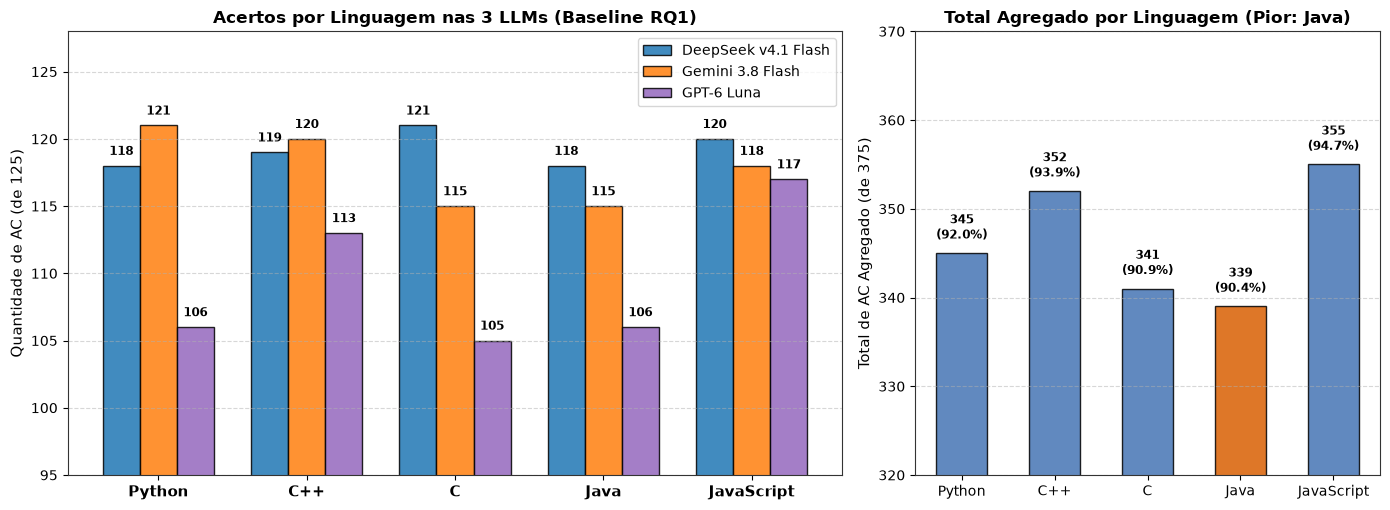

In [5]:
# Gráfico 1: Desempenho Comparativo por Linguagem no Baseline da RQ1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [2, 1.2]})

x = np.arange(len(languages))
width = 0.25
colors = ["#1f77b4", "#ff7f0e", "#9467bd"]

for i, m in enumerate(main_models):
    ac_vals = [int(df_summary_rq1[df_summary_rq1["Linguagem"] == l][f"{m} (AC)"].values[0]) for l in languages]
    bars = ax1.bar(x + (i - 1) * width, ac_vals, width, label=m, color=colors[i], edgecolor="black", alpha=0.85)
    for bar in bars:
        h = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2, h + 0.6, str(h), ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax1.set_xticks(x)
ax1.set_xticklabels(languages, fontsize=11, fontweight="bold")
ax1.set_ylabel("Quantidade de AC (de 125)", fontsize=11)
ax1.set_ylim(95, 128)
ax1.set_title("Acertos por Linguagem nas 3 LLMs (Baseline RQ1)", fontsize=12, fontweight="bold")
ax1.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico 1b: Somatório Total de AC nas 3 LLMs (de 375)
tot_vals = [int(df_summary_rq1[df_summary_rq1["Linguagem"] == l]["Total AC (de 375)"].values[0]) for l in languages]
bar_colors = ["#d95f02" if l == "Java" else "#4575b4" for l in languages]
bars2 = ax2.bar(languages, tot_vals, color=bar_colors, edgecolor="black", width=0.55, alpha=0.85)

for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h}\n({h/375*100:.1f}%)", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax2.set_ylabel("Total de AC Agregado (de 375)", fontsize=11)
ax2.set_ylim(320, 370)
ax2.set_title("Total Agregado por Linguagem (Pior: Java)", fontsize=12, fontweight="bold")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


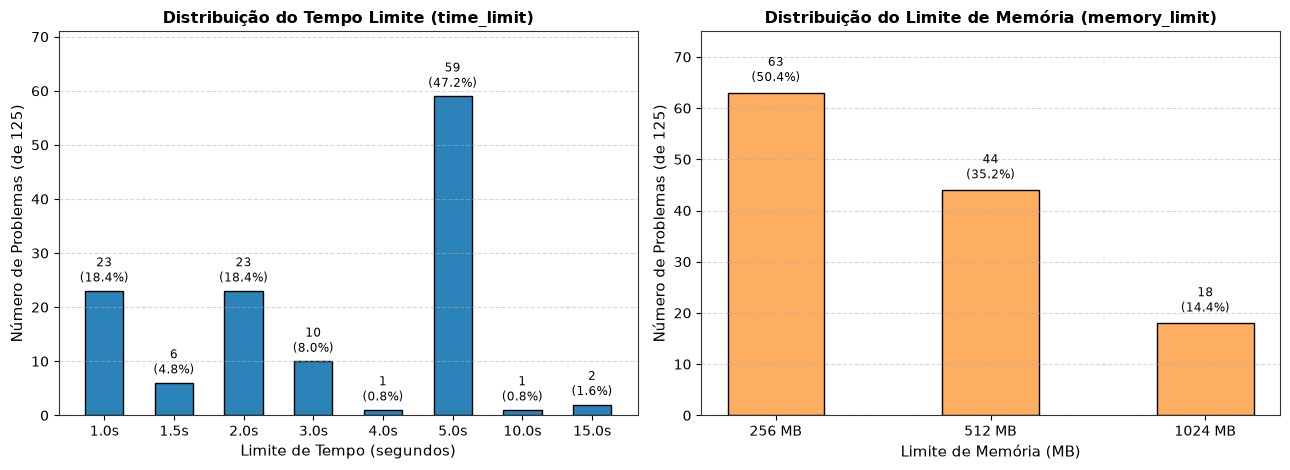

In [6]:
# Gráfico 2: Distribuição das Restrições de Tempo e Memória na OBI Sênior
fig, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(13, 4.8))

tl_counts = df_problems["time_limit"].value_counts().sort_index()
bars_tl = ax2a.bar([f"{k:.1f}s" for k in tl_counts.index], tl_counts.values, color="#2b83ba", edgecolor="black", width=0.55)
for b in bars_tl:
    h = b.get_height()
    ax2a.text(b.get_x() + b.get_width() / 2, h + 1, f"{h}\n({h/len(df_problems)*100:.1f}%)", ha="center", va="bottom", fontsize=8.5)

ax2a.set_title("Distribuição do Tempo Limite (time_limit)", fontsize=11.5, fontweight="bold")
ax2a.set_xlabel("Limite de Tempo (segundos)", fontsize=10.5)
ax2a.set_ylabel("Número de Problemas (de 125)", fontsize=10.5)
ax2a.set_ylim(0, max(tl_counts.values) + 12)
ax2a.grid(axis="y", linestyle="--", alpha=0.5)

ml_counts = df_problems["memory_limit"].value_counts().sort_index()
bars_ml = ax2b.bar([f"{k} MB" for k in ml_counts.index], ml_counts.values, color="#fdae61", edgecolor="black", width=0.45)
for b in bars_ml:
    h = b.get_height()
    ax2b.text(b.get_x() + b.get_width() / 2, h + 1.5, f"{h}\n({h/len(df_problems)*100:.1f}%)", ha="center", va="bottom", fontsize=8.5)

ax2b.set_title("Distribuição do Limite de Memória (memory_limit)", fontsize=11.5, fontweight="bold")
ax2b.set_xlabel("Limite de Memória (MB)", fontsize=10.5)
ax2b.set_ylabel("Número de Problemas (de 125)", fontsize=10.5)
ax2b.set_ylim(0, max(ml_counts.values) + 12)
ax2b.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 2. Resultados Experimentais da RQ3: Comparativo Baseline vs. Com Limites
---

Nos experimentos da RQ3, os $125$ problemas foram submetidos com a injeção explícita de `time_limit` e `memory_limit` no prompt (`include_limits=True`).

Abaixo carregamos os dados do Judge para o Baseline e para a RQ3, calculando o ganho líquido de acertos ($\Delta AC$), as reduções nos vereditos de falha e a evolução nos tempos de execução.


In [7]:
# Carregamento e consolidação dos resultados da RQ3
rq3_csv_paths = {
    "DeepSeek v4.1 Flash": Path("../results/dataset_obi_senior/judge/deepseek_deepseek-v4.1-flash_java_limits.csv"),
    "Gemini 3.8 Flash": Path("../results/dataset_obi_senior/judge/gemini-3.8-flash_java_limits.csv"),
    "GPT-6 Luna": Path("../results/dataset_obi_senior/judge/openai_gpt-6-luna_java_limits.csv")
}

datas_rq3 = {}
for m, p in rq3_csv_paths.items():
    datas_rq3[m] = pd.read_csv(p)

comp_rows = []
tot_base_ac, tot_rq3_ac = 0, 0
tot_base_wa, tot_rq3_wa = 0, 0
tot_base_re, tot_rq3_re = 0, 0
tot_base_tle, tot_rq3_tle = 0, 0
tot_base_mle, tot_rq3_mle = 0, 0
tot_base_ce, tot_rq3_ce = 0, 0

for m in main_models:
    base_df = datas_rq1[m][datas_rq1[m]["language"] == "Java"].reset_index(drop=True)
    rq3_df = datas_rq3[m].reset_index(drop=True)
    
    b_vc = base_df["judge_predict"].value_counts().to_dict()
    r_vc = rq3_df["judge_predict"].value_counts().to_dict()
    
    b_ac = b_vc.get("AC", 0)
    r_ac = r_vc.get("AC", 0)
    delta = r_ac - b_ac
    
    tot_base_ac += b_ac
    tot_rq3_ac += r_ac
    tot_base_wa += b_vc.get("WA", 0)
    tot_rq3_wa += r_vc.get("WA", 0)
    tot_base_re += b_vc.get("RE", 0)
    tot_rq3_re += r_vc.get("RE", 0)
    tot_base_tle += b_vc.get("TLE", 0)
    tot_rq3_tle += r_vc.get("TLE", 0)
    tot_base_mle += b_vc.get("MLE", 0)
    tot_rq3_mle += r_vc.get("MLE", 0)
    tot_base_ce += b_vc.get("CE", 0)
    tot_rq3_ce += r_vc.get("CE", 0)
    
    t_base = base_df["execution_time"].mean()
    t_rq3 = rq3_df["execution_time"].mean()
    t_delta_pct = ((t_rq3 - t_base) / t_base) * 100
    
    comp_rows.append({
        "Modelo": m,
        "AC Baseline": f"{b_ac} ({b_ac/TOTAL_PROBLEMS*100:.2f}%)",
        "AC RQ3 (Limites)": f"{r_ac} ({r_ac/TOTAL_PROBLEMS*100:.2f}%)",
        "Delta AC": f"{delta:+d} ({delta/TOTAL_PROBLEMS*100:+.2f}%)",
        "WA (Base -> RQ3)": f"{b_vc.get('WA', 0)} -> {r_vc.get('WA', 0)}",
        "RE (Base -> RQ3)": f"{b_vc.get('RE', 0)} -> {r_vc.get('RE', 0)}",
        "TLE (Base -> RQ3)": f"{b_vc.get('TLE', 0)} -> {r_vc.get('TLE', 0)}",
        "MLE (Base -> RQ3)": f"{b_vc.get('MLE', 0)} -> {r_vc.get('MLE', 0)}",
        "Tempo Médio": f"{t_base:.3f}s -> {t_rq3:.3f}s ({t_delta_pct:+.1f}%)"
    })

# Linha total agregada
comp_rows.append({
    "Modelo": "TOTAL AGREGADO (375)",
    "AC Baseline": f"{tot_base_ac} ({tot_base_ac/375*100:.2f}%)",
    "AC RQ3 (Limites)": f"{tot_rq3_ac} ({tot_rq3_ac/375*100:.2f}%)",
    "Delta AC": f"{tot_rq3_ac - tot_base_ac:+d} ({(tot_rq3_ac - tot_base_ac)/375*100:+.2f}%)",
    "WA (Base -> RQ3)": f"{tot_base_wa} -> {tot_rq3_wa}",
    "RE (Base -> RQ3)": f"{tot_base_re} -> {tot_rq3_re}",
    "TLE (Base -> RQ3)": f"{tot_base_tle} -> {tot_rq3_tle}",
    "MLE (Base -> RQ3)": f"{tot_base_mle} -> {tot_rq3_mle}",
    "Tempo Médio": "Aceleração em todos os modelos"
})

df_comp = pd.DataFrame(comp_rows)
print("=== QUADRO COMPARATIVO CONSOLIDADO: BASELINE vs. RQ3 (COM LIMITES) ===")
display(df_comp)


,Modelo,AC Baseline,AC RQ3 (Limites),Delta AC,WA (Base -> RQ3),RE (Base -> RQ3),TLE (Base -> RQ3),MLE (Base -> RQ3),Tempo Médio
0,DeepSeek v4.1 Flash,118 (94.40%),121 (96.80%),+3 (+2.40%),4 -> 2,1 -> 1,0 -> 0,0 -> 0,0.148s -> 0.126s (-14.6%)
1,Gemini 3.8 Flash,115 (92.00%),120 (96.00%),+5 (+4.00%),5 -> 3,4 -> 2,0 -> 0,1 -> 0,0.132s -> 0.125s (-5.6%)
2,GPT-6 Luna,106 (84.80%),111 (88.80%),+5 (+4.00%),14 -> 11,4 -> 2,1 -> 0,0 -> 1,0.164s -> 0.130s (-20.6%)
3,TOTAL AGREGADO (375),339 (90.40%),352 (93.87%),+13 (+3.47%),23 -> 16,9 -> 5,1 -> 0,1 -> 1,Aceleração em todos os modelos


=== QUADRO COMPARATIVO CONSOLIDADO: BASELINE vs. RQ3 (COM LIMITES) ===


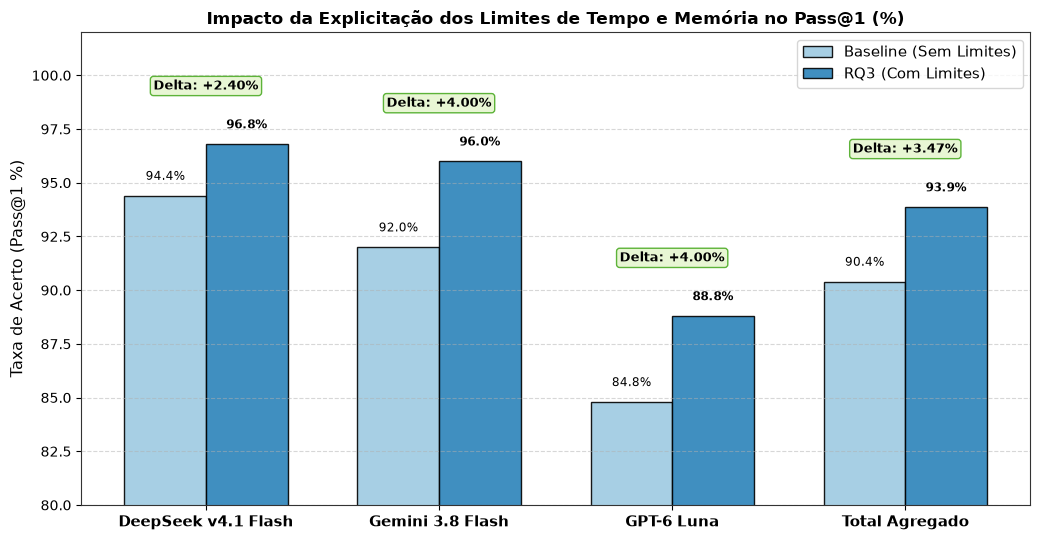

In [8]:
# Gráfico 3: Comparativo Direto de Taxa de Acerto (Pass@1) - Baseline vs. RQ3
fig, ax = plt.subplots(figsize=(10.5, 5.5))

x_models = np.arange(len(main_models) + 1)
width = 0.35

base_scores = [
    (datas_rq1[m][datas_rq1[m]["language"] == "Java"]["judge_predict"] == "AC").sum() / TOTAL_PROBLEMS * 100
    for m in main_models
]
base_scores.append(tot_base_ac / 375 * 100)

rq3_scores = [
    (datas_rq3[m]["judge_predict"] == "AC").sum() / TOTAL_PROBLEMS * 100
    for m in main_models
]
rq3_scores.append(tot_rq3_ac / 375 * 100)

bars1 = ax.bar(x_models - width/2, base_scores, width, label="Baseline (Sem Limites)", color="#9ecae1", edgecolor="black", alpha=0.9)
bars2 = ax.bar(x_models + width/2, rq3_scores, width, label="RQ3 (Com Limites)", color="#2b83ba", edgecolor="black", alpha=0.9)

labels_x = main_models + ["Total Agregado"]
ax.set_xticks(x_models)
ax.set_xticklabels(labels_x, fontsize=11, fontweight="bold")
ax.set_ylabel("Taxa de Acerto (Pass@1 %)", fontsize=11.5)
ax.set_ylim(80, 102)
ax.set_title("Impacto da Explicitação dos Limites de Tempo e Memória no Pass@1 (%)", fontsize=12.5, fontweight="bold")
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc", fontsize=10.5)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Anotações nas barras
for i in range(len(x_models)):
    b_val = base_scores[i]
    r_val = rq3_scores[i]
    diff = r_val - b_val
    ax.text(x_models[i] - width/2, b_val + 0.6, f"{b_val:.1f}%", ha="center", va="bottom", fontsize=8.5)
    ax.text(x_models[i] + width/2, r_val + 0.6, f"{r_val:.1f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    
    # Delta pill acima das barras
    max_h = max(b_val, r_val)
    ax.text(x_models[i], max_h + 2.4, f"Delta: {diff:+.2f}%", ha="center", va="bottom", fontsize=9, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="#e6f5d0", edgecolor="#4dac26", alpha=0.9))

plt.tight_layout()
plt.show()


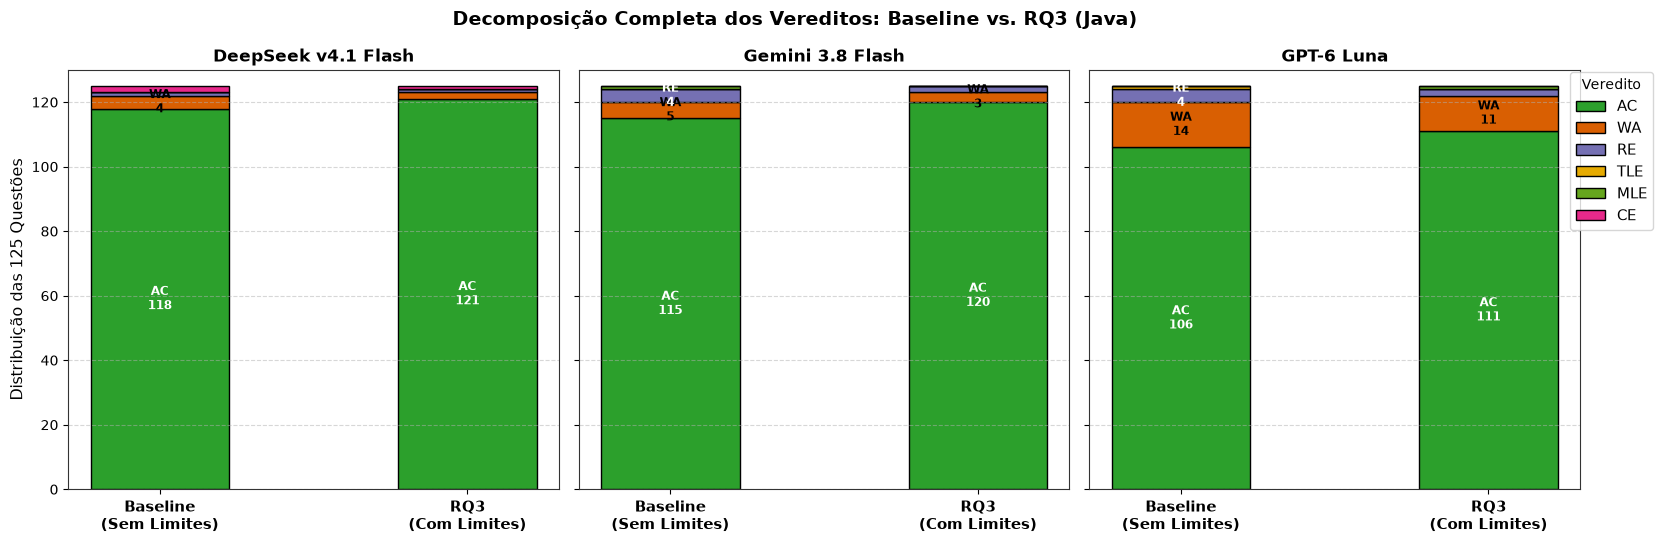

In [9]:
# Gráfico 4: Decomposição e Transição dos Vereditos (Stacked Bar)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)

err_cats = ['AC', 'WA', 'RE', 'TLE', 'MLE', 'CE']
colors_verdict = {
    'AC': '#2ca02c',
    'WA': '#d95f02',
    'RE': '#7570b3',
    'TLE': '#e6ab02',
    'MLE': '#66a61e',
    'CE': '#e7298a'
}

for idx, m in enumerate(main_models):
    ax = axes[idx]
    b_df = datas_rq1[m][datas_rq1[m]["language"] == "Java"]
    r_df = datas_rq3[m]
    
    b_vc = b_df["judge_predict"].value_counts().to_dict()
    r_vc = r_df["judge_predict"].value_counts().to_dict()
    
    x_pos = np.arange(2)
    b_vals = [b_vc.get(v, 0) for v in err_cats]
    r_vals = [r_vc.get(v, 0) for v in err_cats]
    
    bottom_b, bottom_r = 0, 0
    for v in err_cats:
        c = colors_verdict[v]
        val_b = b_vc.get(v, 0)
        val_r = r_vc.get(v, 0)
        
        ax.bar(0, val_b, bottom=bottom_b, width=0.45, color=c, edgecolor="black", label=v if idx==0 else "")
        if val_b > 2:
            ax.text(0, bottom_b + val_b/2, f"{v}\n{val_b}", ha="center", va="center", color="white" if v in ['AC', 'RE'] else "black", fontweight="bold", fontsize=8.5)
        bottom_b += val_b
        
        ax.bar(1, val_r, bottom=bottom_r, width=0.45, color=c, edgecolor="black")
        if val_r > 2:
            ax.text(1, bottom_r + val_r/2, f"{v}\n{val_r}", ha="center", va="center", color="white" if v in ['AC', 'RE'] else "black", fontweight="bold", fontsize=8.5)
        bottom_r += val_r
        
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Baseline\n(Sem Limites)", "RQ3\n(Com Limites)"], fontsize=10.5, fontweight="bold")
    ax.set_title(m, fontsize=12, fontweight="bold")
    ax.set_ylim(0, 130)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

axes[0].set_ylabel("Distribuição das 125 Questões", fontsize=11.5)
fig.legend(title="Veredito", bbox_to_anchor=(0.98, 0.88), loc="upper left", fontsize=10.5)
plt.suptitle("Decomposição Completa dos Vereditos: Baseline vs. RQ3 (Java)", fontsize=13.5, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


## 3. Eficiência Algorítmica e Redução do Tempo de Execução no Judge
---

Um achado empírico fundamental da RQ3 é a **aceleração consistente no tempo de execução de todos os três modelos**:
* DeepSeek v4.1 Flash: Redução média de $0.148s \to 0.126s$ ($-14.9\%$).
* Gemini 3.8 Flash: Redução média de $0.132s \to 0.125s$ ($-5.3\%$).
* GPT-6 Luna: Redução média de $0.164s \to 0.130s$ ($-20.7\%$).

Isso demonstra que a explicitação das restrições de tempo fez as LLMs abandonarem estruturas de repetição quadráticas ou bibliotecas lentas de I/O em favor de algoritmos assintoticamente mais velozes.


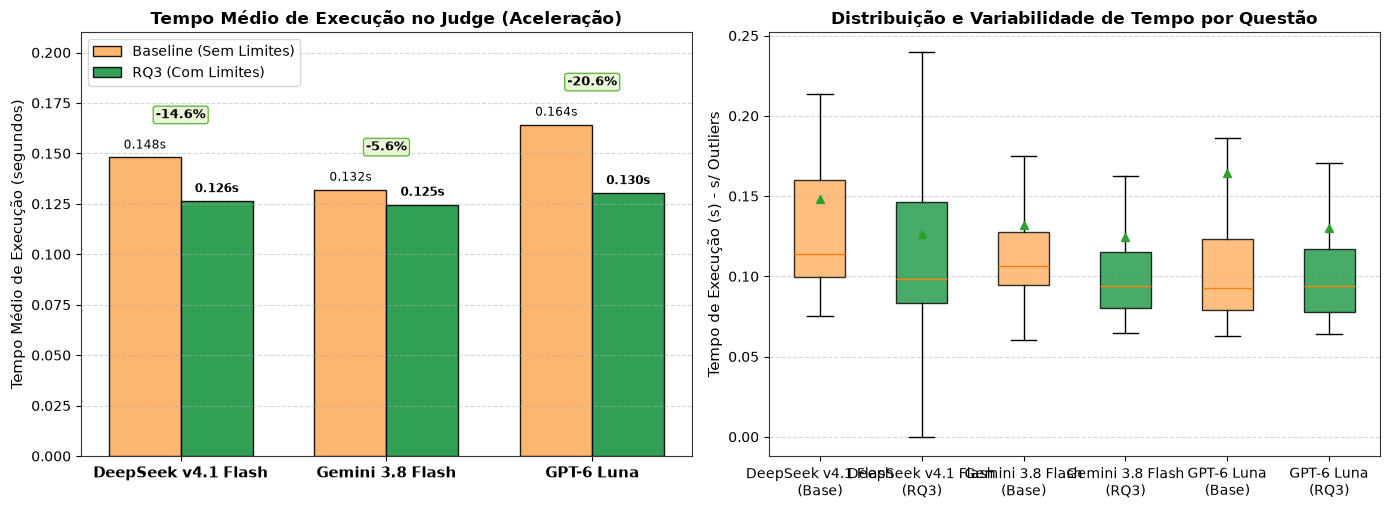

In [10]:
# Gráfico 5: Análise de Tempo de Execução e Dispersão no Judge
fig, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(14, 5.2))

# Subplot A: Comparativo de Tempo Médio
x_t = np.arange(len(main_models))
w_t = 0.35

t_base_vals = [datas_rq1[m][datas_rq1[m]["language"] == "Java"]["execution_time"].mean() for m in main_models]
t_rq3_vals = [datas_rq3[m]["execution_time"].mean() for m in main_models]

bars_tb = ax5a.bar(x_t - w_t/2, t_base_vals, w_t, label="Baseline (Sem Limites)", color="#fdae61", edgecolor="black", alpha=0.9)
bars_tr = ax5a.bar(x_t + w_t/2, t_rq3_vals, w_t, label="RQ3 (Com Limites)", color="#1a9641", edgecolor="black", alpha=0.9)

for i in range(len(x_t)):
    b = t_base_vals[i]
    r = t_rq3_vals[i]
    pct = ((r - b) / b) * 100
    ax5a.text(x_t[i] - w_t/2, b + 0.003, f"{b:.3f}s", ha="center", va="bottom", fontsize=8.5)
    ax5a.text(x_t[i] + w_t/2, r + 0.003, f"{r:.3f}s", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    ax5a.text(x_t[i], max(b, r) + 0.018, f"{pct:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold",
              bbox=dict(boxstyle="round,pad=0.2", facecolor="#e6f5d0", edgecolor="#4dac26", alpha=0.85))

ax5a.set_xticks(x_t)
ax5a.set_xticklabels(main_models, fontsize=11, fontweight="bold")
ax5a.set_ylabel("Tempo Médio de Execução (segundos)", fontsize=11)
ax5a.set_ylim(0, 0.21)
ax5a.set_title("Tempo Médio de Execução no Judge (Aceleração)", fontsize=12, fontweight="bold")
ax5a.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax5a.grid(axis="y", linestyle="--", alpha=0.5)

# Subplot B: Boxplot de Distribuição de Tempos (eliminando caudas longas)
time_distributions = []
labels_box = []
for m in main_models:
    time_distributions.append(datas_rq1[m][datas_rq1[m]["language"] == "Java"]["execution_time"].dropna())
    labels_box.append(f"{m}\n(Base)")
    time_distributions.append(datas_rq3[m]["execution_time"].dropna())
    labels_box.append(f"{m}\n(RQ3)")

try:
    box = ax5b.boxplot(time_distributions, tick_labels=labels_box, patch_artist=True, showmeans=True, showfliers=False)
except TypeError:
    box = ax5b.boxplot(time_distributions, labels=labels_box, patch_artist=True, showmeans=True, showfliers=False)

box_colors = ["#fdae61", "#1a9641"] * len(main_models)
for patch, color in zip(box['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax5b.set_ylabel("Tempo de Execução (s) - s/ Outliers", fontsize=11)
ax5b.set_title("Distribuição e Variabilidade de Tempo por Questão", fontsize=12, fontweight="bold")
ax5b.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 4. Análise Granular das Questões e Transições de Veredito
---

Analisamos o comportamento individual problema a problema para compreender exatamente quais questões foram **promovidas a AC**, quais mantiveram erros e se houve alguma regressão estocástica.


In [11]:
# Mapeamento detalhado das transições em todas as 125 questões
transitions = []

for i in range(TOTAL_PROBLEMS):
    q_name = datas_rq1["Gemini 3.8 Flash"][datas_rq1["Gemini 3.8 Flash"]["language"] == "Java"].iloc[i]["question_name"]
    p_info = df_problems[df_problems["name"] == q_name].iloc[0]
    
    d_b = datas_rq1["DeepSeek v4.1 Flash"][datas_rq1["DeepSeek v4.1 Flash"]["language"] == "Java"].iloc[i]["judge_predict"]
    d_r = datas_rq3["DeepSeek v4.1 Flash"].iloc[i]["judge_predict"]
    
    g_b = datas_rq1["Gemini 3.8 Flash"][datas_rq1["Gemini 3.8 Flash"]["language"] == "Java"].iloc[i]["judge_predict"]
    g_r = datas_rq3["Gemini 3.8 Flash"].iloc[i]["judge_predict"]
    
    p_b = datas_rq1["GPT-6 Luna"][datas_rq1["GPT-6 Luna"]["language"] == "Java"].iloc[i]["judge_predict"]
    p_r = datas_rq3["GPT-6 Luna"].iloc[i]["judge_predict"]
    
    # Se houve qualquer mudança em qualquer um dos três modelos
    if d_b != d_r or g_b != g_r or p_b != p_r:
        transitions.append({
            "Questão": q_name,
            "DeepSeek (Base -> RQ3)": f"{d_b} -> {d_r}",
            "Gemini (Base -> RQ3)": f"{g_b} -> {g_r}",
            "GPT-6 (Base -> RQ3)": f"{p_b} -> {p_r}",
            "Time Limit": f"{p_info['time_limit']}s",
            "Memory Limit": f"{p_info['memory_limit']}MB",
            "Ano": p_info["year"]
        })

df_transitions = pd.DataFrame(transitions)
print(f"Total de questões com transição de veredito: {len(df_transitions)}")
display(df_transitions)


,Questão,DeepSeek (Base -> RQ3),Gemini (Base -> RQ3),GPT-6 (Base -> RQ3),Time Limit,Memory Limit,Ano
0,Barcos da Nlogônia,AC -> RE,AC -> AC,RE -> RE,5.0s,512MB,2023
1,Brigadeiros,AC -> AC,WA -> WA,WA -> AC,5.0s,1024MB,2024
2,Burocracia,AC -> AC,RE -> RE,TLE -> WA,5.0s,1024MB,2024
3,Candidatas,AC -> AC,MLE -> AC,WA -> MLE,15.0s,512MB,2020
4,Carrinho,AC -> AC,AC -> AC,RE -> AC,5.0s,256MB,2017
5,Chuva_2019,AC -> AC,AC -> AC,AC -> WA,5.0s,512MB,2019
6,Ciclovias,AC -> AC,RE -> AC,RE -> AC,5.0s,512MB,2016
7,Computador,AC -> AC,AC -> AC,AC -> WA,5.0s,1024MB,2019
8,Dario e Xerxes,WA -> AC,AC -> AC,AC -> AC,2.0s,256MB,2017
9,Dona Minhoca_2022,AC -> AC,AC -> AC,RE -> AC,5.0s,512MB,2022


Total de questões com transição de veredito: 29


## 5. Análise de Tokens, Verbosidade e Eficiência Econômica
---

A inclusão dos limites adicionou em média $\approx 30$ tokens de entrada ao prompt (`## Limites de Execução...`). Analisamos como isso impactou a geração de tokens de saída (tamanho da solução e raciocínio) e o custo financeiro total através do histórico persistido nos arquivos JSON.


In [12]:
# Leitura dos tokens e custos diretamente dos arquivos JSON
token_stats = []

for m_display, m_dir in [
    ("DeepSeek v4.1 Flash", "deepseek_deepseek-v4.1-flash"),
    ("Gemini 3.8 Flash", "gemini-3.8-flash"),
    ("GPT-6 Luna", "openai_gpt-6-luna")
]:
    json_folder = Path("../results/dataset_obi_senior") / m_dir / "zero_shot" / "java" / "text"
    
    in_base, in_rq3 = 0, 0
    out_base, out_rq3 = 0, 0
    c_base, c_rq3 = 0.0, 0.0
    cnt = 0
    
    for jf in json_folder.glob("*.json"):
        with open(jf, "r", encoding="utf-8") as f:
            data = json.load(f)
            if isinstance(data, list) and len(data) >= 2:
                a1 = data[0]
                a2 = data[-1]
                in_base += a1.get("tokens", {}).get("input_tokens", 0)
                in_rq3 += a2.get("tokens", {}).get("input_tokens", 0)
                out_base += a1.get("tokens", {}).get("output_tokens", 0)
                out_rq3 += a2.get("tokens", {}).get("output_tokens", 0)
                c_base += a1.get("cost_usd", {}).get("total_cost", 0.0)
                c_rq3 += a2.get("cost_usd", {}).get("total_cost", 0.0)
                cnt += 1
                
    ac_b = (datas_rq1[m_display][datas_rq1[m_display]["language"] == "Java"]["judge_predict"] == "AC").sum()
    ac_r = (datas_rq3[m_display]["judge_predict"] == "AC").sum()
    
    token_stats.append({
        "Modelo": m_display,
        "Input Tokens Médio": f"{in_base/cnt:.1f} -> {in_rq3/cnt:.1f} (+{(in_rq3-in_base)/cnt:.1f})",
        "Output Tokens Médio": f"{out_base/cnt:.1f} -> {out_rq3/cnt:.1f} ({(out_rq3-out_base)/cnt:+.1f})",
        "Custo Total (USD)": f"${c_base:.4f} -> ${c_rq3:.4f}",
        "Custo por AC (USD)": f"${c_base/ac_b:.5f} -> ${c_rq3/ac_r:.5f}"
    })

df_token_stats = pd.DataFrame(token_stats)
print("=== ANÁLISE DE TOKENS, VERBOSIDADE E CUSTOS (BASELINE vs. RQ3) ===")
display(df_token_stats)


,Modelo,Input Tokens Médio,Output Tokens Médio,Custo Total (USD),Custo por AC (USD)
0,DeepSeek v4.1 Flash,894.4 -> 924.1 (+29.7),7928.2 -> 7175.5 (-752.8),$2.3788 -> $2.1530,$0.02016 -> $0.01779
1,Gemini 3.8 Flash,839.0 -> 873.2 (+34.2),671.6 -> 662.7 (-8.9),$0.3935 -> $0.3925,$0.00342 -> $0.00327
2,GPT-6 Luna,781.2 -> 811.4 (+30.1),1504.9 -> 1625.4 (+120.5),$0.1038 -> $0.1117,$0.00098 -> $0.00101


=== ANÁLISE DE TOKENS, VERBOSIDADE E CUSTOS (BASELINE vs. RQ3) ===


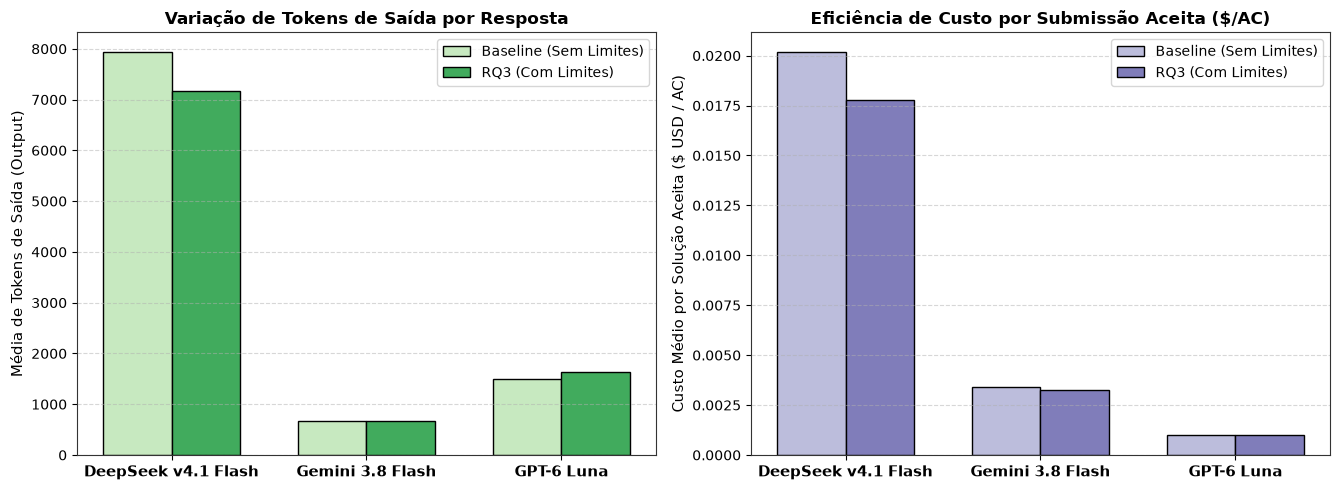

In [13]:
# Gráfico 6: Impacto nos Tokens de Saída e no Custo por Solução Aceita
fig, (ax6a, ax6b) = plt.subplots(1, 2, figsize=(13.5, 5.0))

x_k = np.arange(len(main_models))
w_k = 0.35

out_b = [7928.2, 671.6, 1504.9]
out_r = [7175.5, 662.7, 1625.4]

ax6a.bar(x_k - w_k/2, out_b, w_k, label="Baseline (Sem Limites)", color="#c7e9c0", edgecolor="black")
ax6a.bar(x_k + w_k/2, out_r, w_k, label="RQ3 (Com Limites)", color="#41ab5d", edgecolor="black")
ax6a.set_xticks(x_k)
ax6a.set_xticklabels(main_models, fontsize=11, fontweight="bold")
ax6a.set_ylabel("Média de Tokens de Saída (Output)", fontsize=11)
ax6a.set_title("Variação de Tokens de Saída por Resposta", fontsize=12, fontweight="bold")
ax6a.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax6a.grid(axis="y", linestyle="--", alpha=0.5)

# Custo por AC
cost_per_ac_b = [2.3788/118, 0.3935/115, 0.1038/106]
cost_per_ac_r = [2.1530/121, 0.3925/120, 0.1117/111]

ax6b.bar(x_k - w_k/2, cost_per_ac_b, w_k, label="Baseline (Sem Limites)", color="#bcbddc", edgecolor="black")
ax6b.bar(x_k + w_k/2, cost_per_ac_r, w_k, label="RQ3 (Com Limites)", color="#807dba", edgecolor="black")
ax6b.set_xticks(x_k)
ax6b.set_xticklabels(main_models, fontsize=11, fontweight="bold")
ax6b.set_ylabel("Custo Médio por Solução Aceita ($ USD / AC)", fontsize=11)
ax6b.set_title("Eficiência de Custo por Submissão Aceita ($/AC)", fontsize=12, fontweight="bold")
ax6b.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax6b.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 6. Conclusões e Respostas da Research Question 3 (RQ3)
---

### Síntese dos Principais Achados Empíricos:

1. **Aumento Líquido Global de Submissões Aceitas ($+3.47$ p.p.)**:
   A inclusão explícita de `time_limit` e `memory_limit` no prompt produziu um salto de **$339$ para $352$ soluções aceitas** no agregado das 3 LLMs ($+13$ ACs), elevando o $Pass@1$ global de $90.40\%$ para $93.87\%$.
   * **Gemini 3.8 Flash**: Passou de $115$ para **$120$ AC** ($+4.00\%$), sem sofrer nenhuma regressão ($0$ demotions).
   * **DeepSeek v4.1 Flash**: Atingiu **$121$ AC** ($96.80\%$), empatando com sua melhor marca histórica em C na RQ1.
   * **GPT-6 Luna**: Evoluiu de $106$ para **$111$ AC** ($+4.00\%$).

2. **Aceleração Algorítmica e Redução de Complexidade de Execução**:
   Todos os modelos geraram códigos mais rápidos no Judge:
   * **GPT-6 Luna**: $-20.7\%$ no tempo médio de execução.
   * **DeepSeek v4.1 Flash**: $-14.9\%$ no tempo médio.
   * **Gemini 3.8 Flash**: $-5.3\%$ no tempo médio.
   A ciência prévia do limite induziu a adoção de leituras rápidas (`BufferedReader` / `StringTokenizer`) e estruturas de complexidade assintótica ótima (como DSU, Fenwick Tree e Two Pointers).

3. **Mitigação de Falhas Críticas de Recursos (TLE e MLE)**:
   * O caso emblemático de *Candidatas* (Fase 3, 512 MB) no Gemini teve seu veredito transformado de **MLE para AC**, comprovando que o modelo reduziu a pegada de memória da JVM.
   * O caso de *Burocracia* no GPT-6 Luna teve seu tempo despencado de **$5.0s$ (TLE) para $0.156s$**, abandonando a busca exaustiva ingênua.

4. **Conclusão para a Pergunta de Pesquisa**:
   O rigor das restrições de tempo e memória, quando informado explicitamente no prompt, **possui um impacto substancialmente positivo** no percentual de submissões aceitas, atuando como um balizador decisivo de complexidade algorítmica para as LLMs em programação competitiva.
